# Estudio contextual · AA · prototipos promedio

**Prototipos BERT RAW 768D · mean100/WordNet · K80**

Se separa la rama `prototypes` del notebook recibido, conservando su estructura y sus resultados guardados.
Se organiza como antecedente AA: un vector promedio por palabra en ambos lados. Este archivo no implementa
las otras ocho condiciones del estudio contextual controlado ni acredita por sí solo la identidad de su AA final.

| K | Modelo | Ridge | Estado del cierre original |
|---:|---|---:|---|
| 80 | H_BETA_LINEAR_Z | 0.1 | Exploratorio GK97P/GK98P; CORE3 no certificado |

El traslado de carpeta no modifica el dataset, el modelo ni los resultados desfavorables.


## 1. Preparación

Abre el notebook desde la carpeta descomprimida `ProyectoTesis`. Instala `requirements.txt` en tu entorno.
Las rutas se leen de `rutas_resultados.json` en la raíz; si no existe, se busca `Results` dentro de ProyectoTesis.
El programa `localizar_resultados.py` puede generar ese JSON a partir de tu carpeta `Exp2def`.

El modo de lectura es **`reuse_only`**: no se ejecutan clasificadores, calibraciones ni nuevos ajustes.
Sí se reconstruyen predicciones y superficies desde los coeficientes guardados para comprobar su correspondencia.
Las entradas originales se conservan y las salidas de revisión se escriben en `SalidasRevision`.

**Salidas ya visibles:** provienen del notebook enviado y, para W2V K40, de las exportaciones verificadas incluidas.
No prueban que las carpetas externas de GloVe/AA estén presentes en esta entrega. Para cargar objetos en memoria
y volver a generar sus informes, esas carpetas deben estar disponibles. Consulta `RESULTADOS_PENDIENTES.md`.


In [ ]:
from pathlib import Path
import sys
from dataclasses import replace
import pandas as pd
from IPython.display import display

# Encuentra el código desde la raíz, el experimento estático o el notebook AA.
REPO = next((candidate.resolve()
             for parent in (Path.cwd(), *Path.cwd().parents)
             for candidate in (parent, parent / "EstudioEstatico/ExperimentoEstatico")
             if (candidate / "CodigoComun/reutilizacion.py").is_file()), None)
if REPO is None:
    raise FileNotFoundError("Abre ProyectoTesis en VS Code y selecciona un kernel dentro del proyecto.")
sys.path.insert(0, str(REPO / "CodigoComun"))
import exp2_pipeline_integrated as exp
import reutilizacion as reuse
from seleccion_estructural import auditar_estructura
if Path(exp.__file__).resolve() != (REPO / "CodigoComun/exp2_pipeline_integrated.py").resolve():
    raise RuntimeError("Otro módulo está cargado. Reinicia el kernel.")
print("Proyecto:", REPO)
print("Módulo compartido:", exp.PROTOCOL_VERSION)


In [ ]:
MODE = "reuse_only"
DATASET_KEYS = ("prototypes",)
CONFIG = reuse.configurar(REPO, DATASET_KEYS)
RESULTS = {}
display(reuse.protocolo_principal(DATASET_KEYS))
display(exp.preflight(CONFIG))


## 2. Contrato científico y lectura de resultados

- **Diseño:** ocho Category Words y K vecinos restringidos por clase; RAW; pares de clases diferentes; 51 semillas de split y 10 de clasificador. `frequency_threshold=2` exige más de dos palabras. Se conserva el split estático del módulo original: los competidores se fijan antes de seleccionar VALIDATION y deben permanecer en TRAIN.
- **Recuperación:** una iteración; se recuperan tanto TRAIN como VALIDATION; ensemble original de seis clasificadores. No se cambia la memoria por omisión LOCO: LOCO es sensibilidad estadística de las clases, no una ablación de patrones de la red.
- **Calibración HFY:** un λ por dataset/K/red/split, estimado exclusivamente con TRAIN y fijo para toda la grilla. Se equipara la fracción efectiva de memorias atendidas a MHNCS mediante error cuadrático en logaritmos, con igual peso clase/beta. (eta_{mathrm{efectivo}}=lambdaeta_{mathrm{nominal}}). No se calibra usando FAR ni VALIDATION.
- **Superficie empírica:** 98 betas nominales, 0.010–0.495; similitud estandarizada dentro de clase sobre palabras únicas FULL; intersección COMMON de rangos de las ocho clases; cinco bins uniformes. Cada celda promedia tasas por palabra dentro de clase/bin y después las ocho clases con igual peso. No se agrupan exposiciones como si todas las palabras pesaran igual.
- **Validez A:** los 51 splits conservan las ocho clases y no descartan consultas; COMMON tiene longitud positiva; cada combinación clase/bin contiene al menos una palabra; los conteos tienen la cobertura y los denominadores exactos. No se reduce el número de bins para salvar una configuración.

Los tres comportamientos se resumen con pendientes OLS globales: $T_1>0$ (más similitud, más FAR), $T_2<0$ (más beta, menos FAR), $T_3<0$ (beta atenúa la pendiente de similitud). Estos signos son criterios globales de superficie; no afirman monotonía celda a celda.

| Campo | Qué comprueba |
|---|---|
| E | Los tres signos en la superficie empírica FULL |
| R_EMP / R_CLASS | Los signos empíricos resisten las ocho omisiones de clase |
| M_primary | Los signos del modelo FULL en la malla primaria de esa auditoría |
| R_MODEL_primary | Los ocho reajustes LOCO del modelo conservan los signos |
| ALL_FITS_STABLE | Convergencia numérica de todos los ajustes requeridos |
| B_report | Siete diagnósticos de soporte/concentración del error; **no veta ni selecciona K/modelo** |

Se conservan MATCHED5, calculada en las posiciones observadas y agregada con los mismos cinco bins, y GRID30, que describe la superficie funcional en 30 puntos. El módulo y las salidas originales usan GRID30 como malla primaria, también en AA; se corrigió aquí la descripción contradictoria del notebook fuente, sin cambiar sus cálculos.

La familia/ridge se eligió entre 51 candidatas con CV estratificada por **palabra completa**, 5 repeticiones × 5 folds. Todos los betas de una palabra permanecen juntos. Se aplican dos filtros one-SE (log-loss y fidelidad de superficie), luego complejidad, mayor regularización e identificador. Los signos y LOCO no entran en la selección. Esta CV es condicional al experimento/calibración ya fijados y participó en la selección: no representa validación final independiente.

FULL y cada LOCO reconstruyen el preprocesamiento y ajustan coeficientes con las clases presentes; familia/ridge y calibración permanecen fijas. No se predice la clase omitida. No se eliminan clases porque su omisión produzca un resultado desfavorable.

## 3. Ejecución por dataset

Las siguientes celdas verifican y presentan cada dataset por separado. Si una etapa se interrumpe, corrige la causa y repite su celda: los checkpoints completos se conservan. Un archivo ausente o una pausa numérica no se convierte en un rechazo científico.

La verificación del historial de K vuelve a evaluar los gates sobre los artefactos disponibles. No reinicia una búsqueda distinta ni promueve K100 de Prototipos, que quedó fuera del cierre final.

### Prototipos · K80 exploratorio

Se conserva GK97P/GK98P, incluyendo Normmax. La auditoría no encontró una configuración CORE3 aprobada en el alcance concluido. K80 no se declara primera K válida. El fallo de B es descriptivo; los fallos E/R permanecen visibles.

In [9]:
if "prototypes" in CONFIG.datasets:
    RESULTS["prototypes"] = exp.run_dataset(CONFIG, "prototypes", plots=False, replay_k=True)
    exp.display_tables(RESULTS["prototypes"], names=(
        "K_selection", "K_replay", "calibration", "empirical_CORE3", "B_report", "final_status"
    ))

Prototipos BERT RAW : 3.825 checkpoints CV autenticados; sin repetir ajustes.
Prototipos BERT RAW: mhncs_softmax, FULL + 8 LOCO completos.
Prototipos BERT RAW: hfy_entmax_a15, FULL + 8 LOCO completos.
Prototipos BERT RAW: hfy_normmax_g2, FULL + 8 LOCO completos.

BEGIN_COPY_TABLE::STATIC_RECTOR_FULL
       network  stable  n_words  n_classes  active_parameters  alpha       T1        T2        T3     E  E_5bins  RMSE_in_sample_5bins  gradient_inf
 mhncs_softmax    True      414          8                128    0.1 0.006111 -0.017979 -0.014978  True     True              0.012173  1.216131e-11
hfy_entmax_a15    True      414          8                128    0.1 0.006126  0.000678 -0.000698 False    False              0.010423  6.604755e-12
hfy_normmax_g2    True      414          8                128    0.1 0.006862 -0.004944 -0.005464  True     True              0.010892  8.486710e-12
END_COPY_TABLE::STATIC_RECTOR_FULL

BEGIN_COPY_TABLE::STATIC_RECTOR_LOCO_SUMMARY
       network  FULL_E

,K,status,CORE3,networks_evaluated,class_omissions_passed,forensic_GK94P_scope,selected_exploratory_K80
0,20,STRUCTURAL_FAIL,False,NaN,NaN,True,False
1,30,STRUCTURAL_FAIL,False,NaN,NaN,True,False
2,40,STRUCTURAL_FAIL,False,NaN,NaN,True,False
3,50,STRUCTURAL_FAIL,False,NaN,NaN,True,False
4,60,STRUCTURAL_FAIL,False,NaN,NaN,True,False
5,70,STRUCTURAL_FAIL,False,NaN,NaN,True,False
6,80,E_FAIL,False,2.0,8.0,True,True
7,90,E_FAIL,False,2.0,8.0,True,False



Prototipos BERT RAW · K_replay


,K,status,A,E_CORE3,R_CORE3,networks_evaluated,class_omissions_passed,K80_exploratory_closure,automatic_CORE3_fallback
0,20,STRUCTURAL_FAIL,False,False,False,0,NaN,False,False
1,30,STRUCTURAL_FAIL,False,False,False,0,NaN,False,False
2,40,STRUCTURAL_FAIL,False,False,False,0,NaN,False,False
3,50,STRUCTURAL_FAIL,False,False,False,0,NaN,False,False
4,60,STRUCTURAL_FAIL,False,False,False,0,NaN,False,False
5,70,STRUCTURAL_FAIL,False,False,False,0,NaN,False,False
6,80,E_FAIL,True,False,False,2,8.0,True,False
7,90,E_FAIL,True,False,False,2,8.0,False,False



Prototipos BERT RAW · calibration


,K,calibration_uses_errors,calibration_uses_validation,lambda_at_boundary,lambda_value,maximum_recall_delta,n_memories,n_objective_evaluations,network,objective_calibrated,objective_reduction_fraction,objective_reference,seconds,split_seed,train_array_sha,train_words_sha
0,80,False,False,False,0.207066,3.552714e-15,429,11,hfy_entmax_a15,0.244190,0.884826,2.120191,120.051809,0,8ebb93c75a32fb436870b94ecb24c746bb6feebfce7b89...,a3c3d71a4a2d3707f5572a4af57bbeef539b0d9775e85f...
1,80,False,False,False,0.206708,7.105427e-15,429,11,hfy_entmax_a15,0.247663,0.883765,2.130708,120.304837,1,2dcb176fb1249de4994ccc7dcf1cf3ec9cc54d8417b3b9...,643e7e69128016b33f8d73873a85d571f0394bf9bd5a65...
2,80,False,False,False,0.207241,7.105427e-15,429,11,hfy_entmax_a15,0.244644,0.885967,2.145377,120.345122,2,004d26c2c164cac81963f26da376a3769862ffa0dccc94...,9024198d56baabd3bc8bb7f001b423f0861b4c87bafec3...
3,80,False,False,False,0.206622,5.329071e-15,429,11,hfy_entmax_a15,0.242939,0.886633,2.142940,120.024267,3,40c58d677a7bb983d6d8084dcf5e709913d720d0d7de93...,a1d487415bce550ee2607905b66e7f50cb31ebcd4577dc...
4,80,False,False,False,0.208139,7.105427e-15,429,11,hfy_entmax_a15,0.247950,0.883400,2.126507,120.120298,4,686e8b21be7a40f0109197e099bf66224fe9ad58cc49e9...,d95c352ddb229ae566abf220fdb90782a6185ada3a87d2...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,80,False,False,False,0.171972,6.217249e-15,429,9,hfy_normmax_g2,0.153203,0.937041,2.433367,68.728146,46,12e86f3805ed96b3b87de94990348b76f6655cbf7bfa86...,2a4a2145572bcfb7dc5fe1c3ecd7c2ec778ac8ed2f68df...
98,80,False,False,False,0.171527,3.552714e-15,429,10,hfy_normmax_g2,0.154381,0.935852,2.406628,75.769465,47,8eafefd89cd079d3927cc79a31e556aa54d581f192ad0e...,daf5e5a3648ea6a272ef528d7164042dd42928cc4c0ed1...
99,80,False,False,False,0.172100,9.769963e-15,429,9,hfy_normmax_g2,0.158884,0.934763,2.435473,66.811845,48,dd8f165ae123793691257041f703aff145c96d2164c895...,98422894459183583cbfb6527ff0fb2b5e45c72ae13163...
100,80,False,False,False,0.172873,8.881784e-15,429,9,hfy_normmax_g2,0.157596,0.935084,2.427713,66.727590,49,4b6e0f754db2e342e3c73d041716f53782191b6907de9a...,8eada24e545dd2b1f86b800ca704839795923e19a6af1b...


... (2 outputs left out)


Prototipos BERT RAW · B_report


,network,rule,metric,observed,operator,threshold,passed,continuous_margin,role
0,mhncs_softmax,B1,n_positive_classes,8.000000,>=,4.0,True,0.500000,DESCRIPTIVE_NOT_A_VETO
1,mhncs_softmax,B2,max_class_error_share,0.616763,<,0.5,False,-0.189316,DESCRIPTIVE_NOT_A_VETO
2,mhncs_softmax,B3,effective_error_classes,2.305041,>=,2.0,True,0.132337,DESCRIPTIVE_NOT_A_VETO
3,mhncs_softmax,B4,n_positive_words,105.000000,>=,8.0,True,0.923810,DESCRIPTIVE_NOT_A_VETO
4,mhncs_softmax,B5,max_word_error_share,0.100750,<,0.5,True,0.798500,DESCRIPTIVE_NOT_A_VETO
5,mhncs_softmax,B6,effective_error_words,19.210485,>=,4.0,True,0.791780,DESCRIPTIVE_NOT_A_VETO
6,mhncs_softmax,B7,common_error_retention_efficiency,1.044382,>=,0.5,True,0.521248,DESCRIPTIVE_NOT_A_VETO
7,hfy_entmax_a15,B1,n_positive_classes,8.000000,>=,4.0,True,0.500000,DESCRIPTIVE_NOT_A_VETO
8,hfy_entmax_a15,B2,max_class_error_share,0.620206,<,0.5,False,-0.193816,DESCRIPTIVE_NOT_A_VETO
9,hfy_entmax_a15,B3,effective_error_classes,2.269739,>=,2.0,True,0.118841,DESCRIPTIVE_NOT_A_VETO



Prototipos BERT RAW · final_status


,network,A,E_empirical,empirical_LOCO_passed,R_EMP,M_matched5,model_LOCO_passed_5,R_MODEL_matched5,M_grid30,model_LOCO_passed_30,R_MODEL_grid30,primary_model_grid,M_primary,R_MODEL_primary,B_report,ALL_FITS_STABLE,CORE3_component,empirical_model5_E_disagreements,model5_grid30_E_disagreements
0,mhncs_softmax,True,True,7,False,True,7,False,True,7,False,grid30,True,False,False,True,False,0,0
1,hfy_entmax_a15,True,False,1,False,False,1,False,False,2,False,grid30,False,False,False,True,False,0,1
2,hfy_normmax_g2,True,False,2,False,True,7,False,True,7,False,grid30,True,False,False,True,False,6,0


**Heatmaps agregados y LOCO.** Se conserva la paleta morado–amarillo, beta nominal en el eje horizontal, similitud en el vertical y similitud mayor arriba. Relación alto/ancho 0.08; sin suavizado ni interpolación. Escala de color común entre las tres redes/FULL/LOCO dentro del dataset. Se muestran 3 empíricos FULL, 3 modelos FULL y 24 modelos LOCO.


MHNCS Softmax — superficies agregadas FULL: 1.c empírica y 1.d modelada


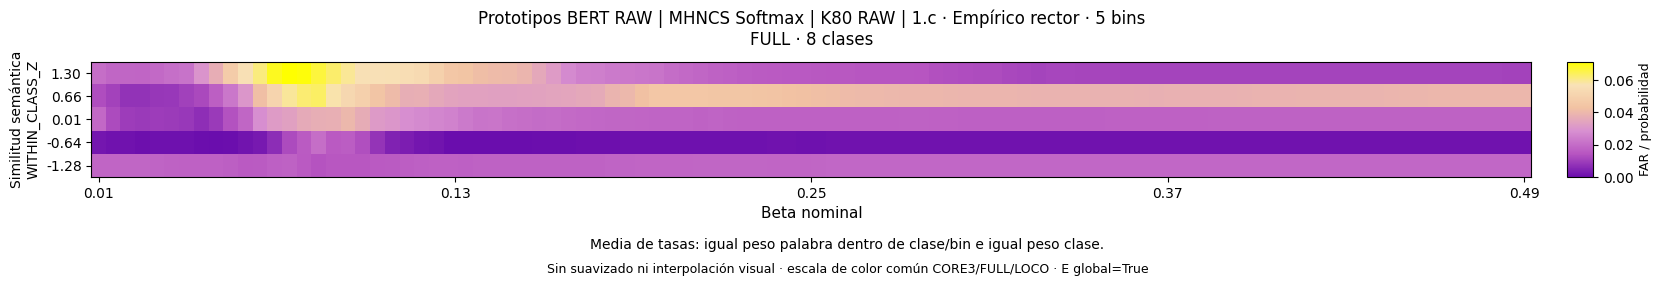

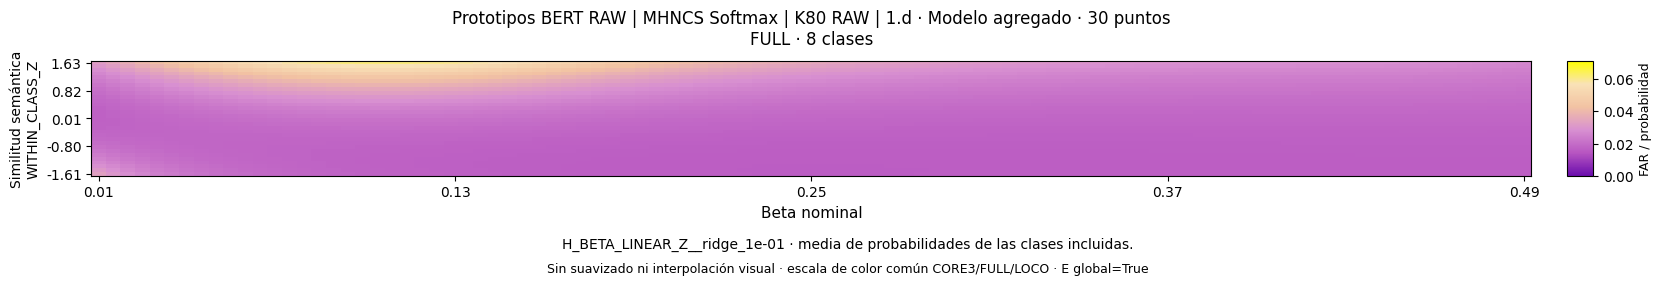


HFY Entmax α=1.5 — superficies agregadas FULL: 1.c empírica y 1.d modelada


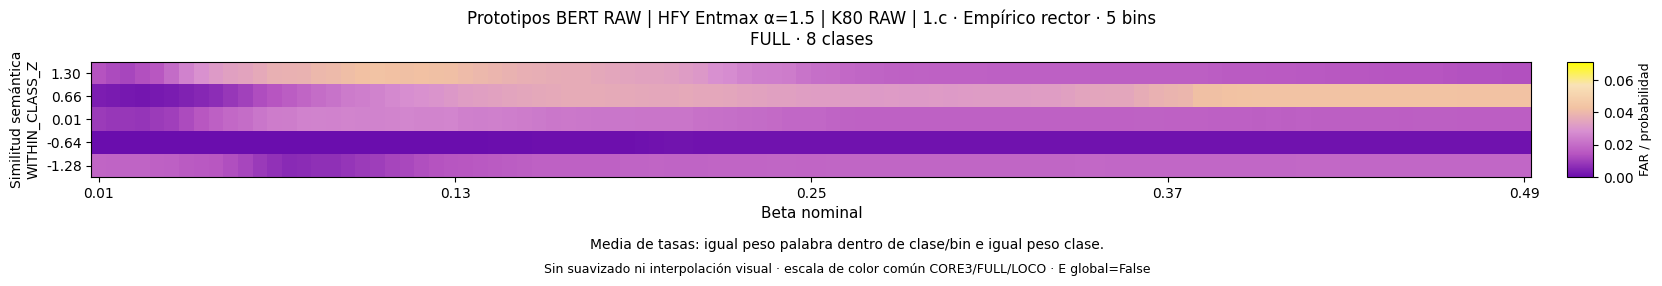

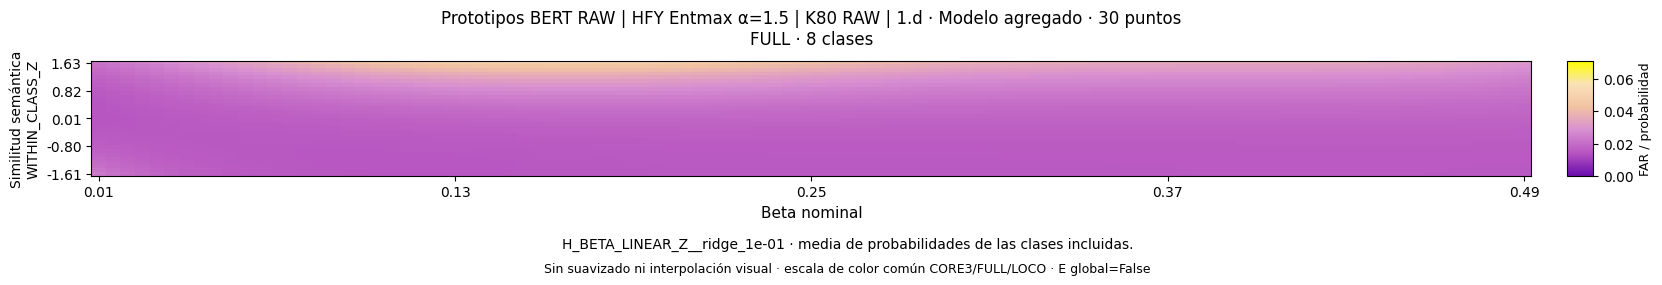


HFY Normmax γ=2 — superficies agregadas FULL: 1.c empírica y 1.d modelada


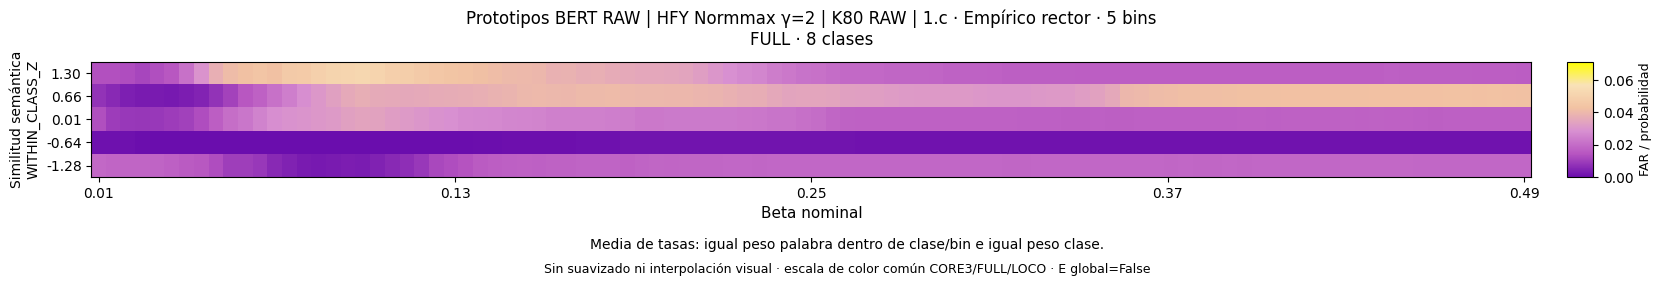

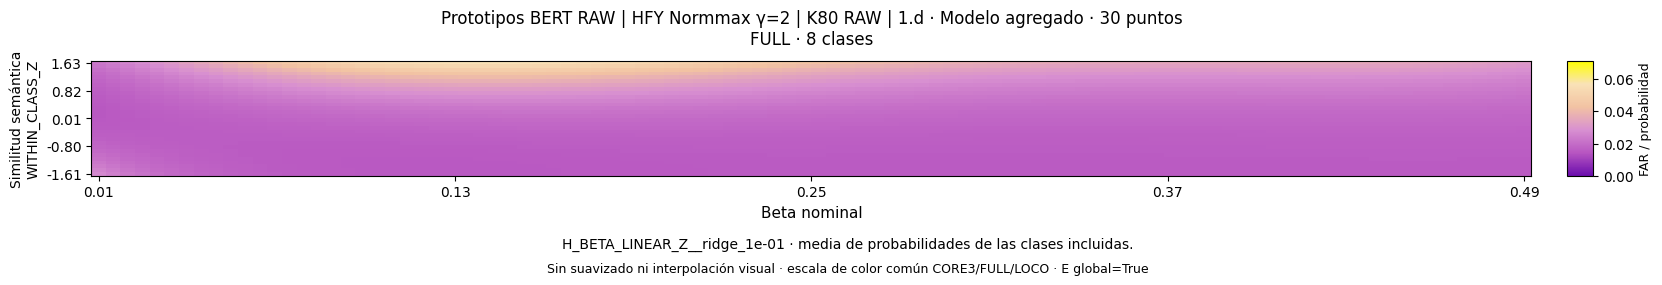


MHNCS Softmax — ocho heatmaps LOCO con reajuste


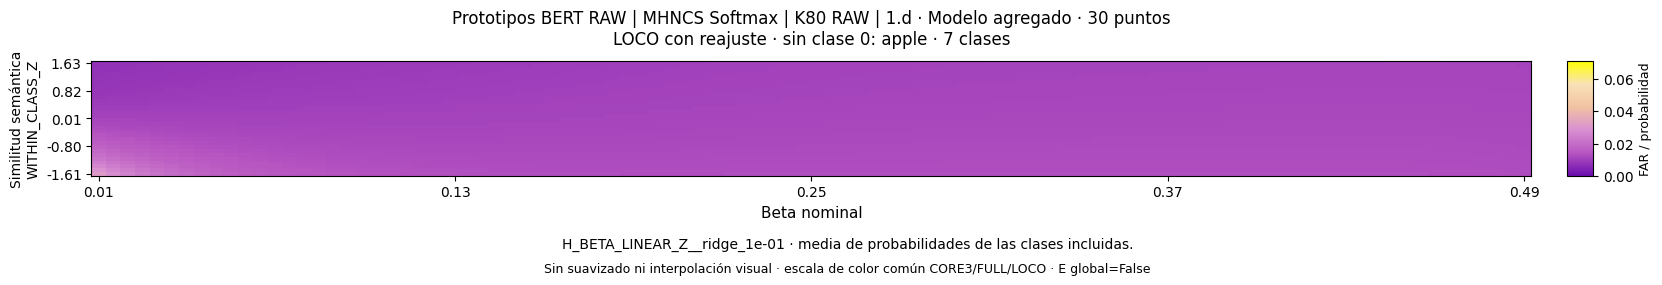

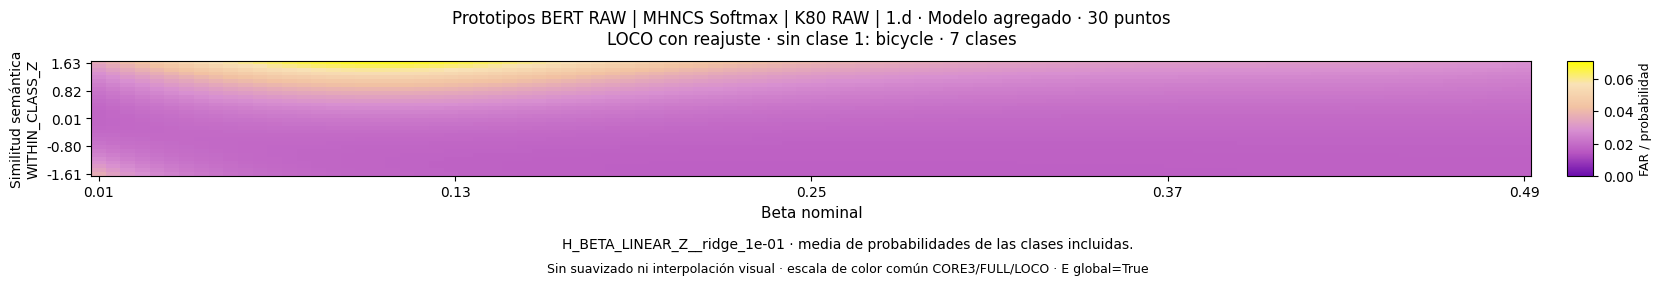

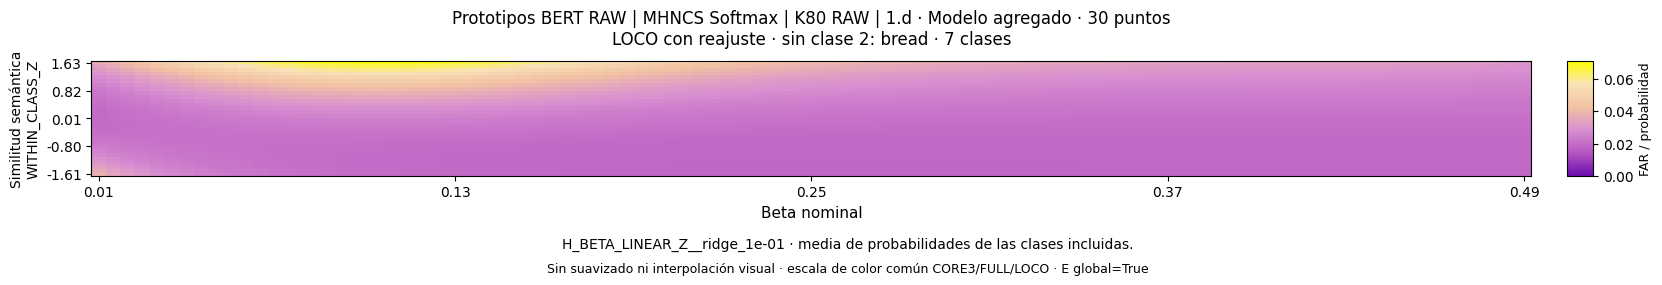

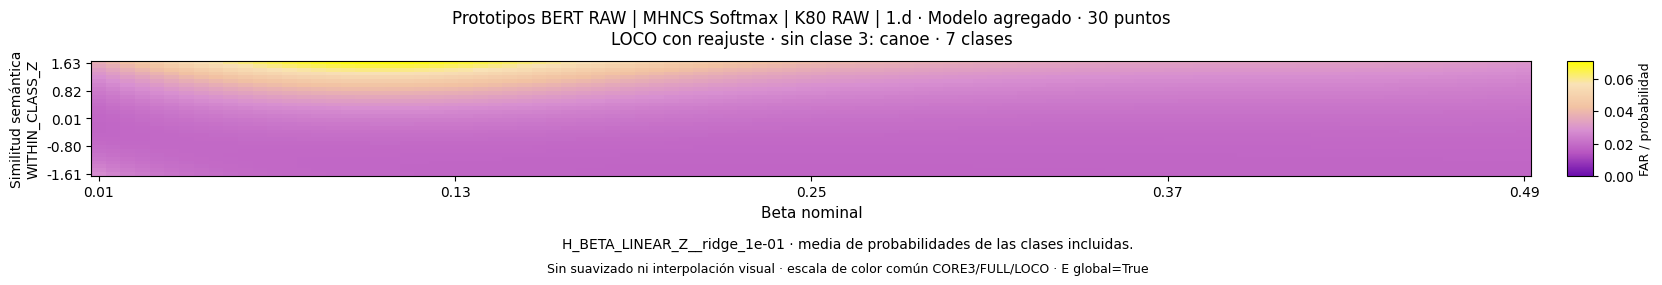

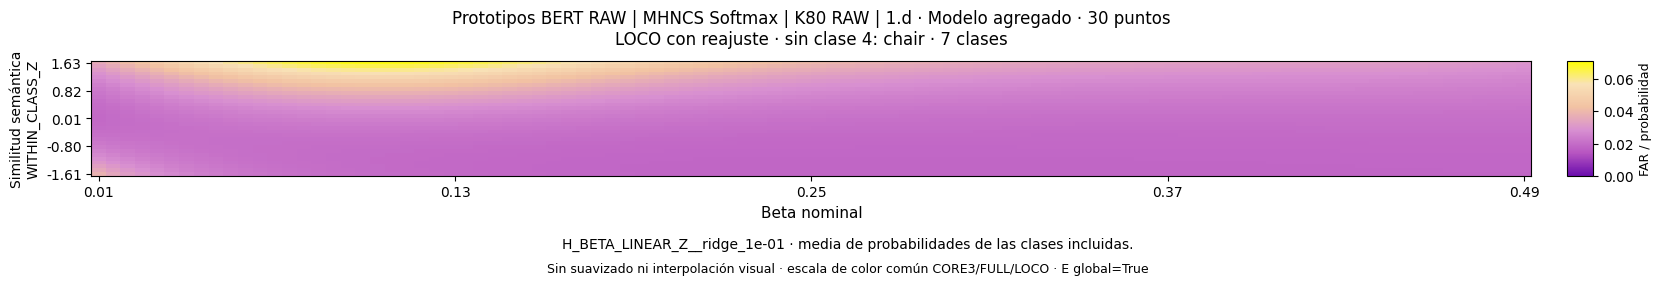

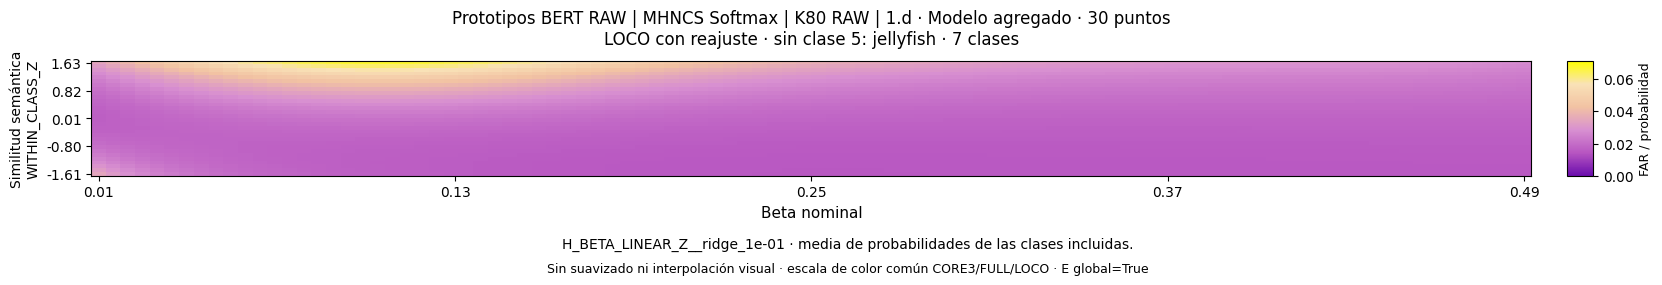

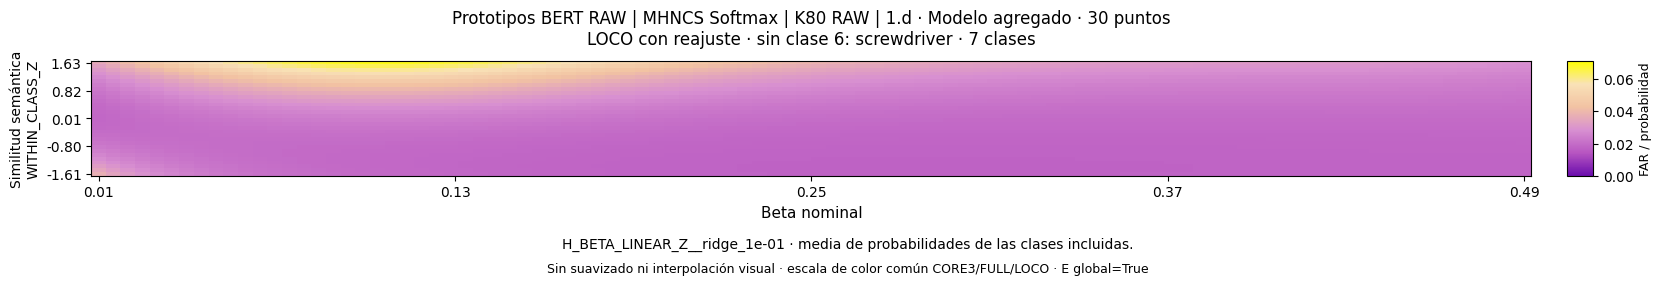

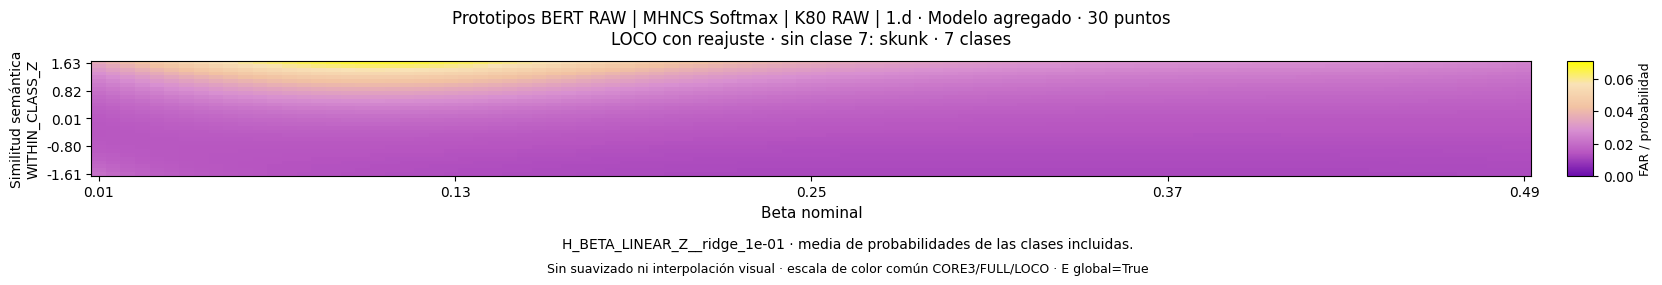


HFY Entmax α=1.5 — ocho heatmaps LOCO con reajuste


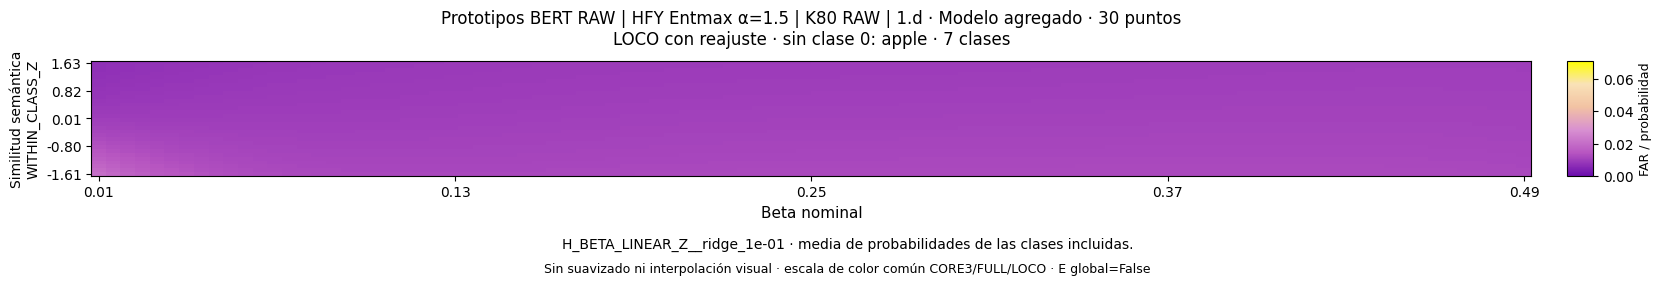

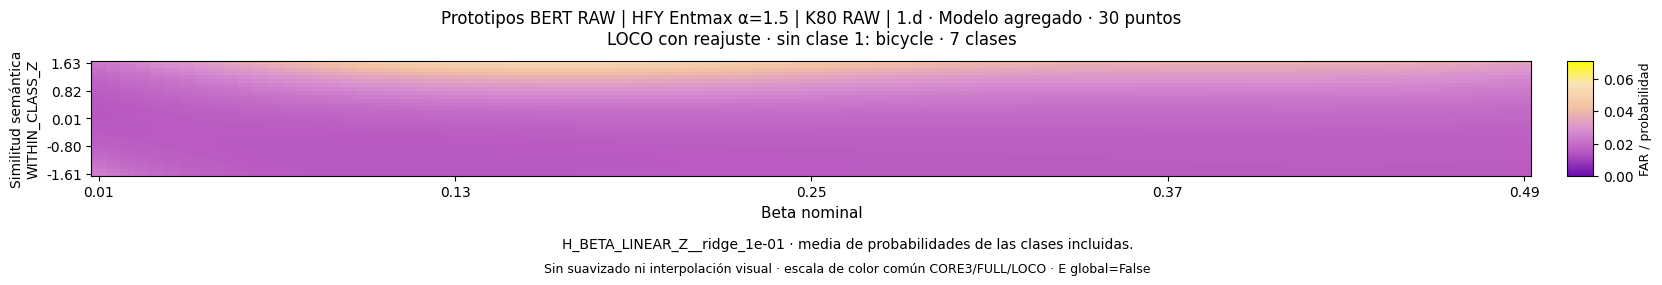

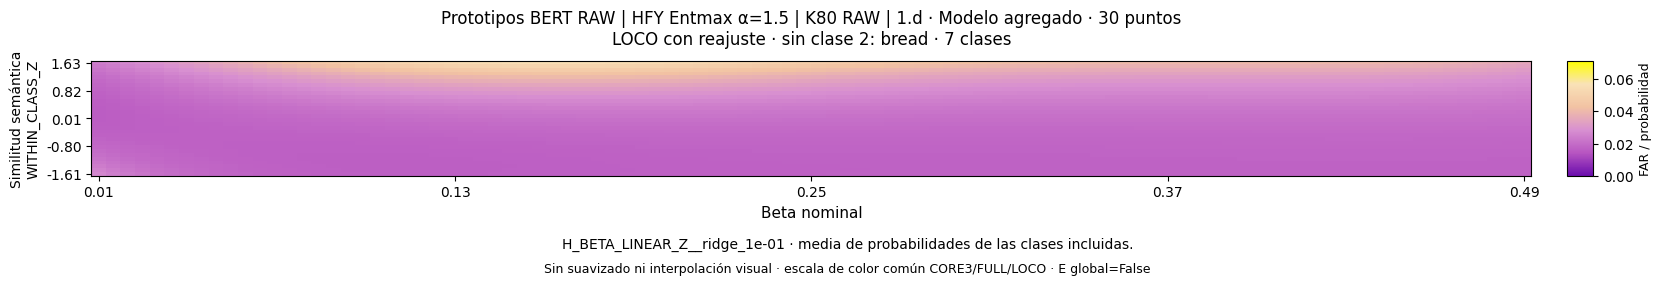

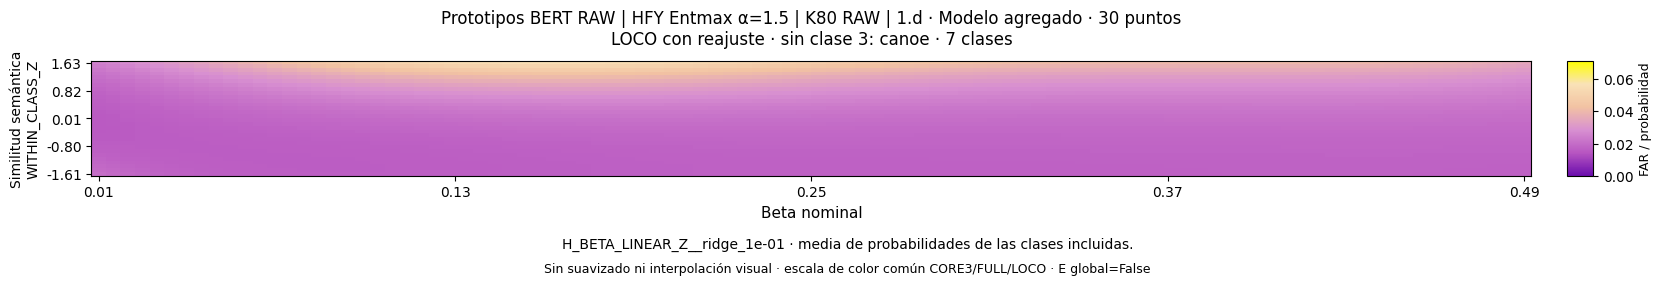

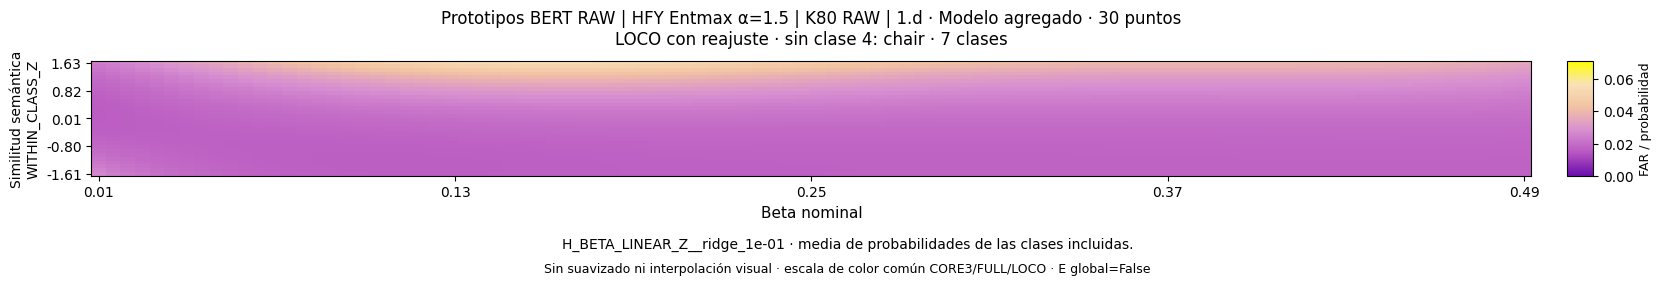

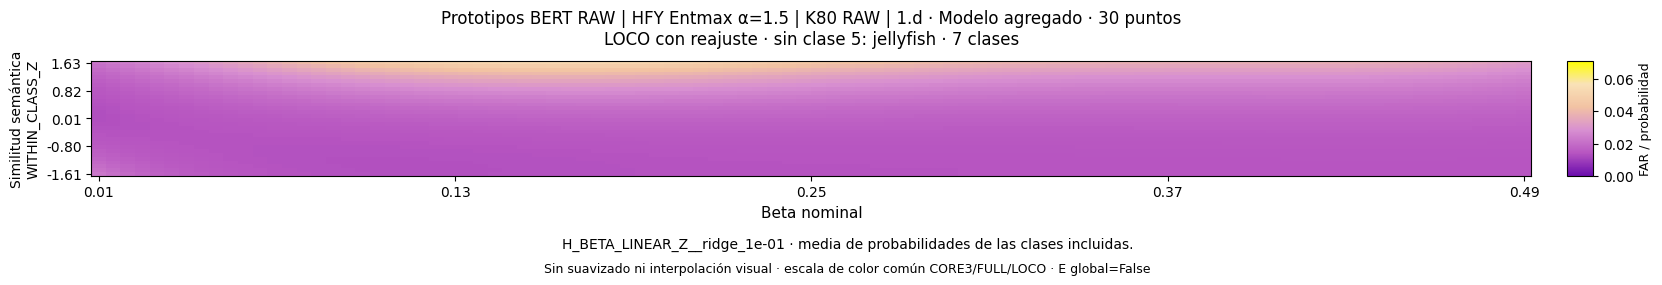

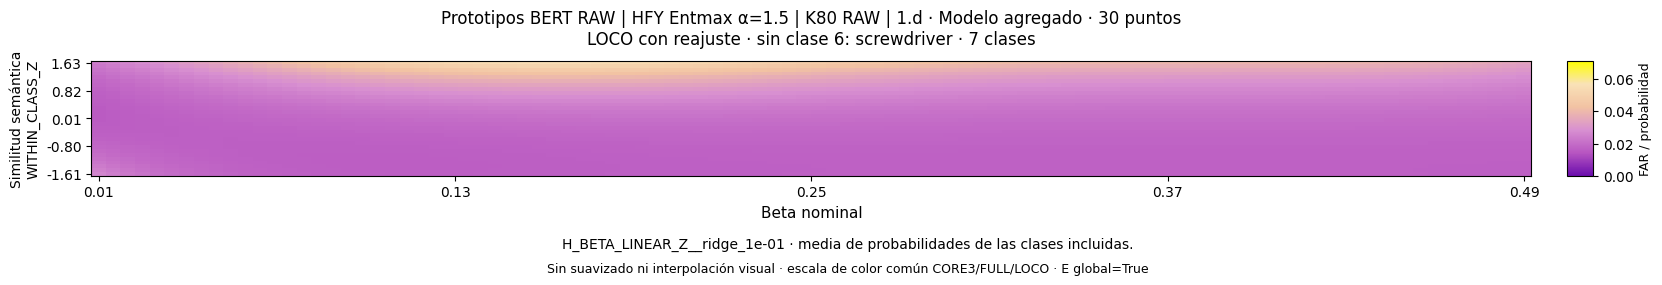

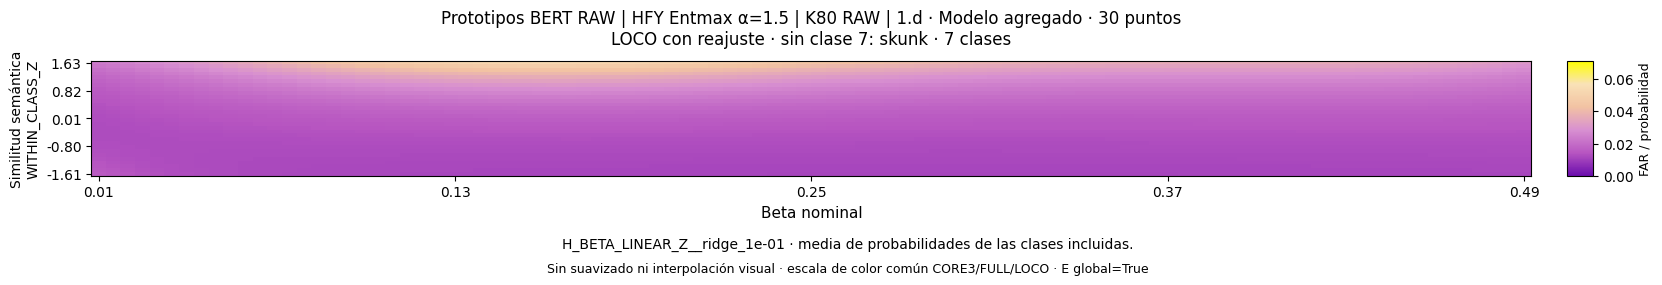


HFY Normmax γ=2 — ocho heatmaps LOCO con reajuste


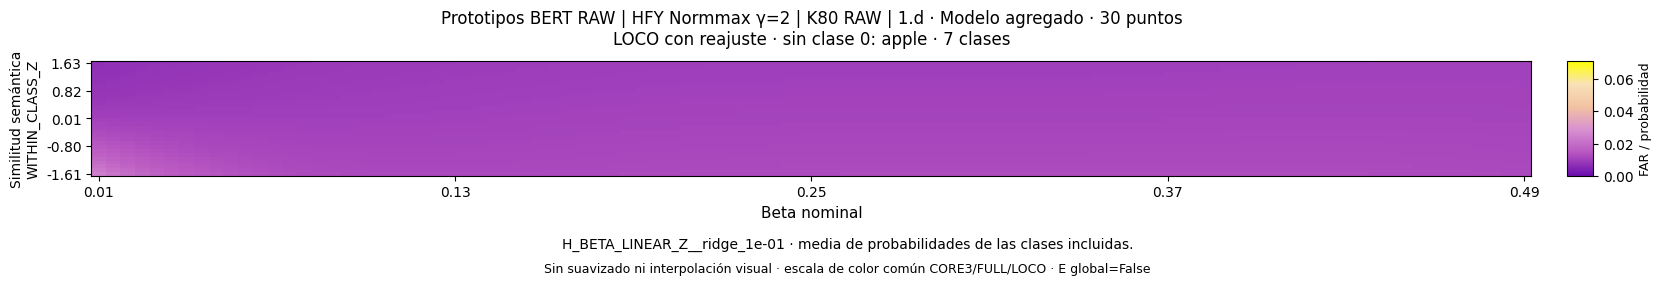

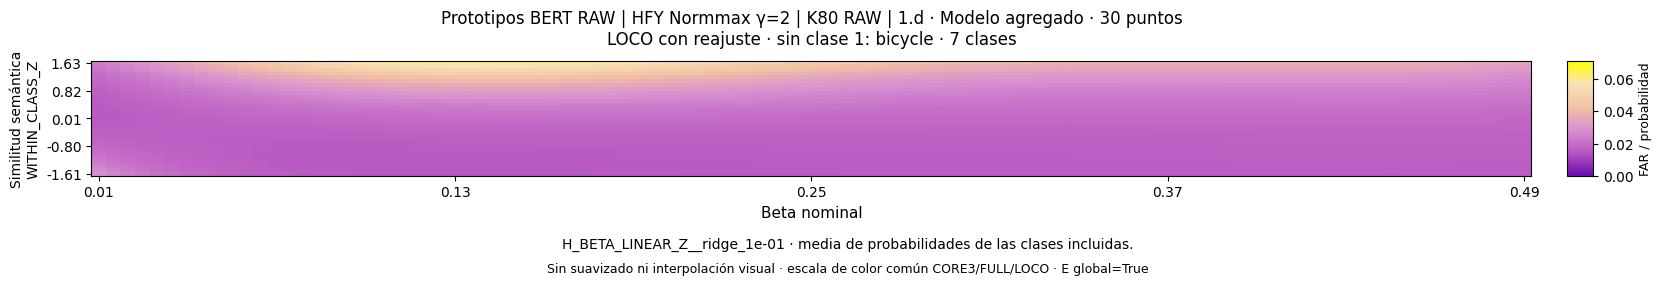

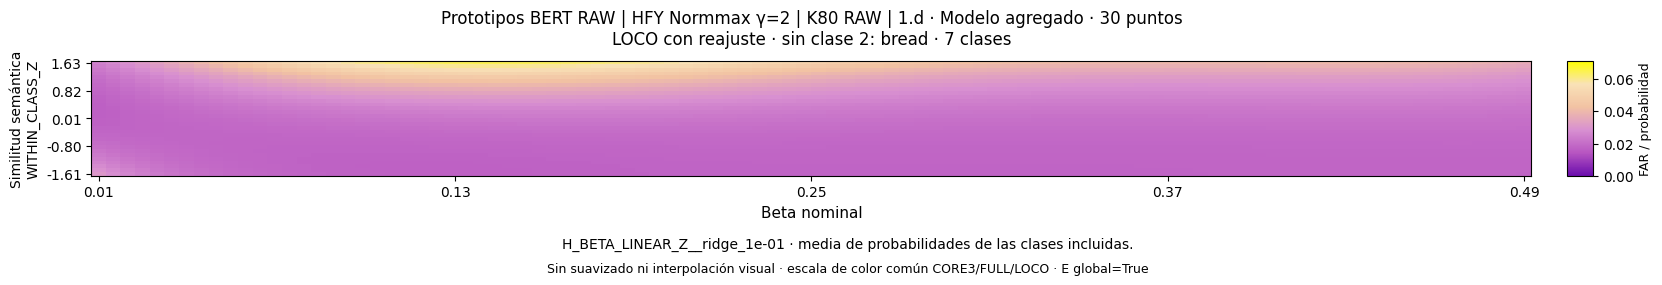

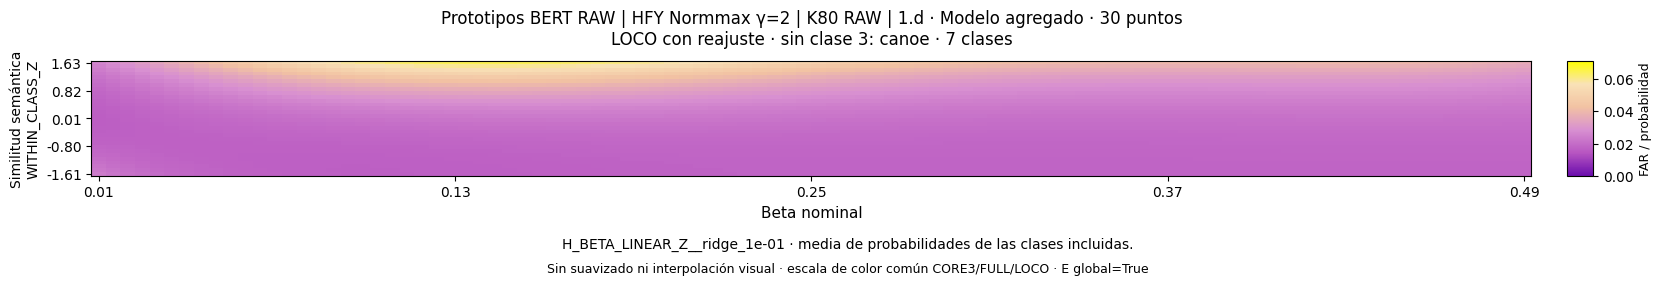

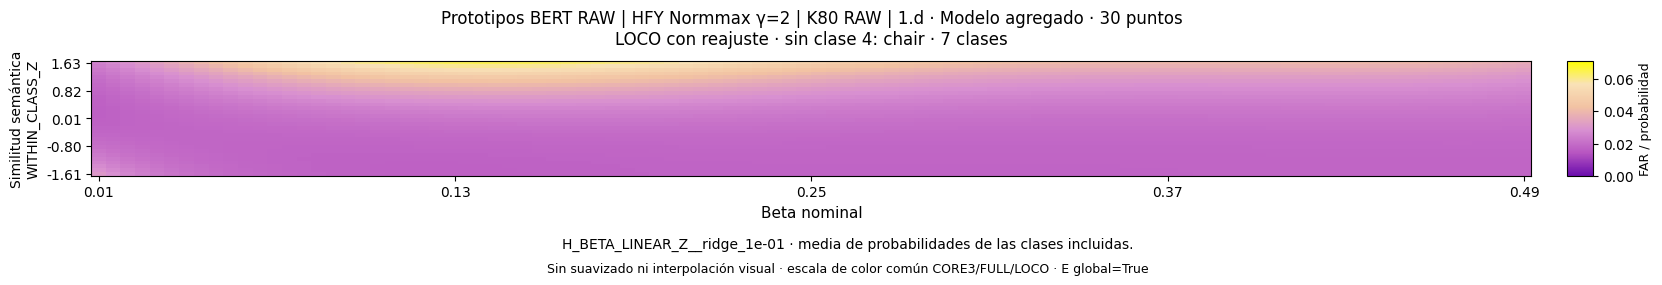

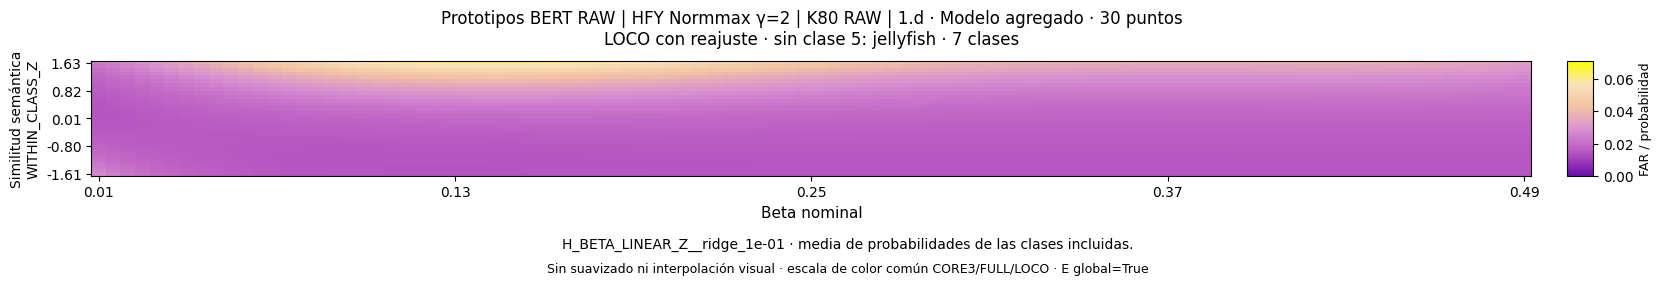

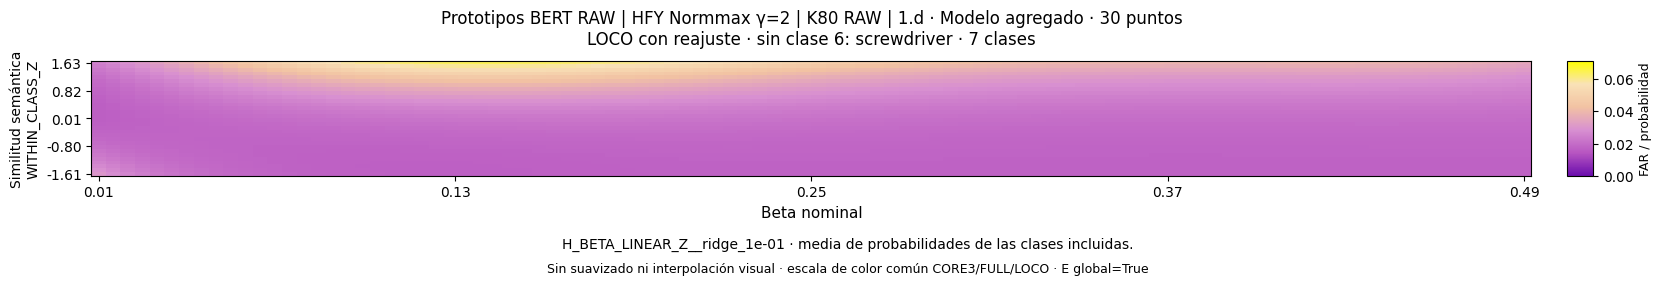

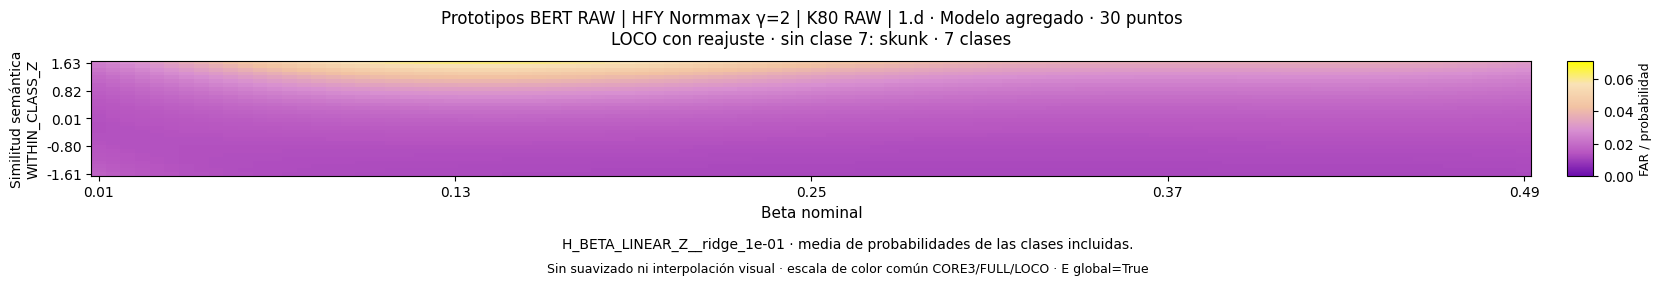

Heatmaps: 3 empíricos + 3 modelos agregados FULL + 24 LOCO. Carpeta: \\?\C:\Users\jisaa\Workspace\Tesis\Exp2def\Results\EXPERIMENTO_ESTATICO_OFICIAL\prototypes\run_1c806189caa884299a63\FULL_LOCO\refit_323d8f1b6e82c0a7fe67\figures


In [10]:
if "prototypes" in RESULTS:
    exp.plot_dataset(RESULTS["prototypes"], heatmaps=True, fit_quality=False, oof=False)

**Ajuste y sensibilidad.** Los paneles A/B/C comparan las curvas de las mallas nativas: empírica de cinco bins y modelo de 30 puntos. Las métricas matched5 y OOF se calculan por separado, sobre soporte comparable. El panel B de concordancia gráfica no es el informe estructural `B_report`.

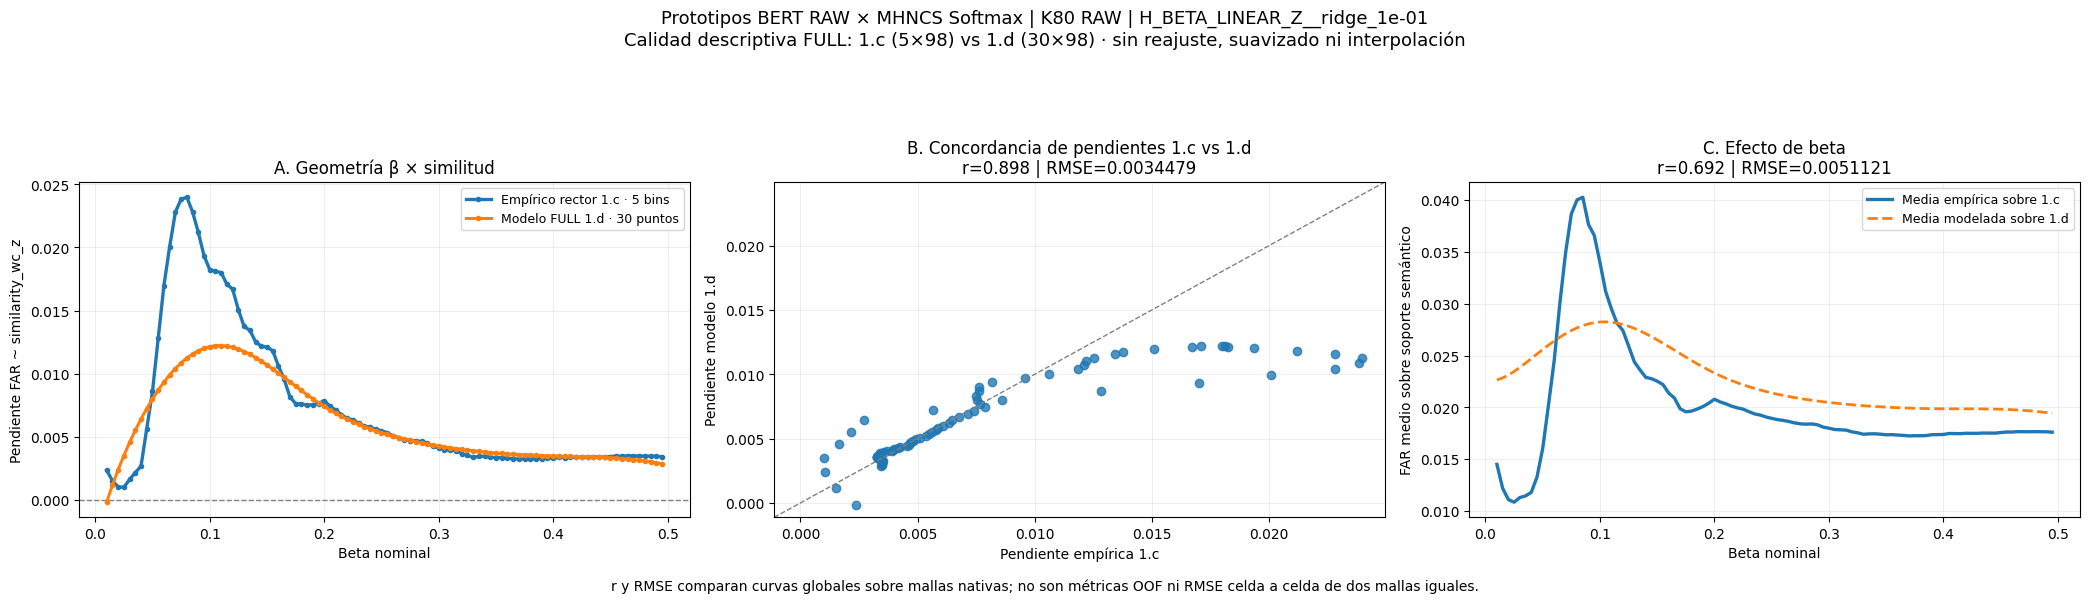

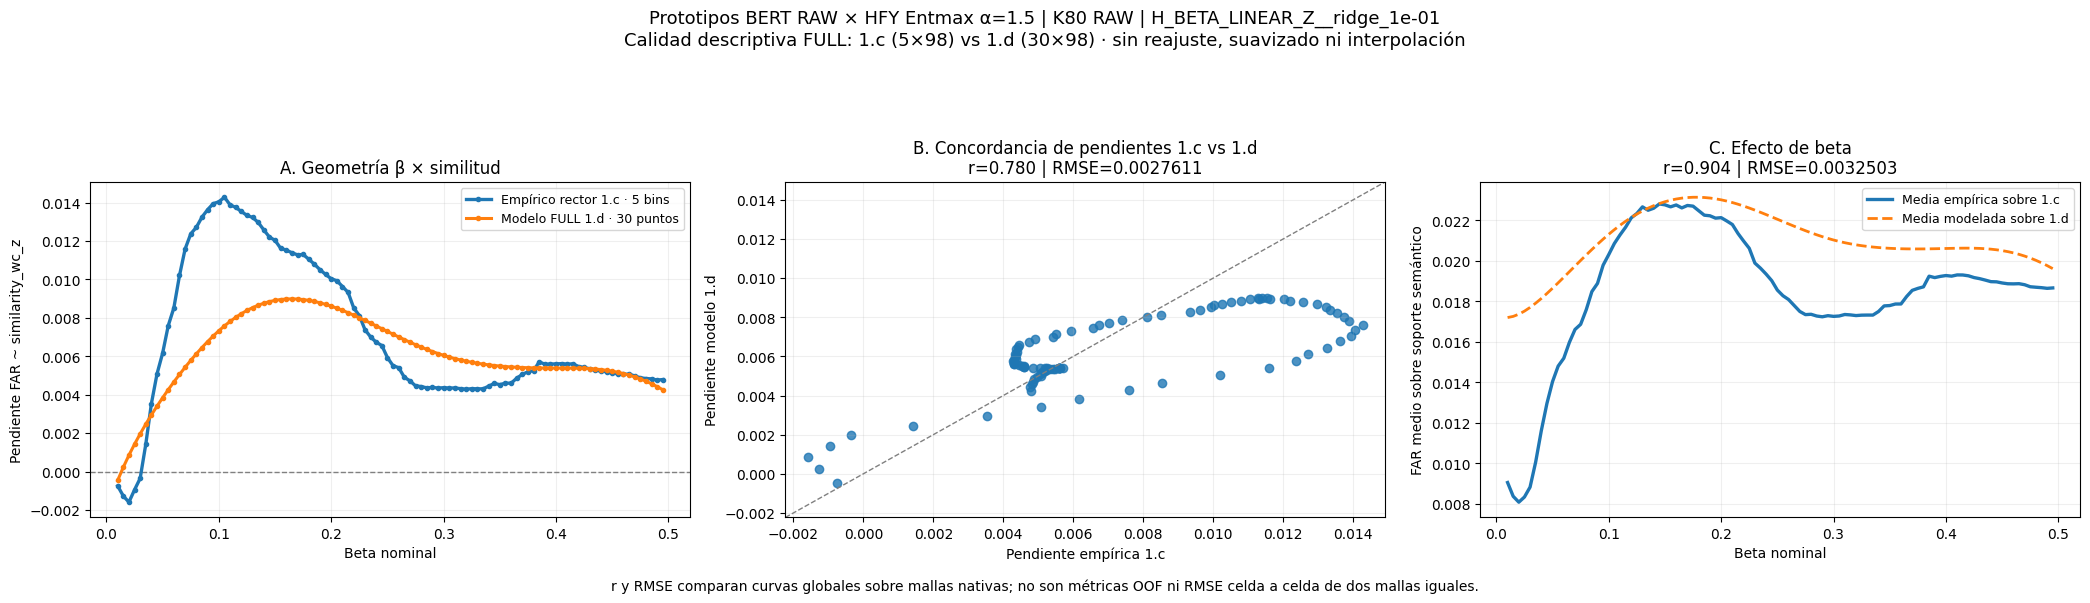

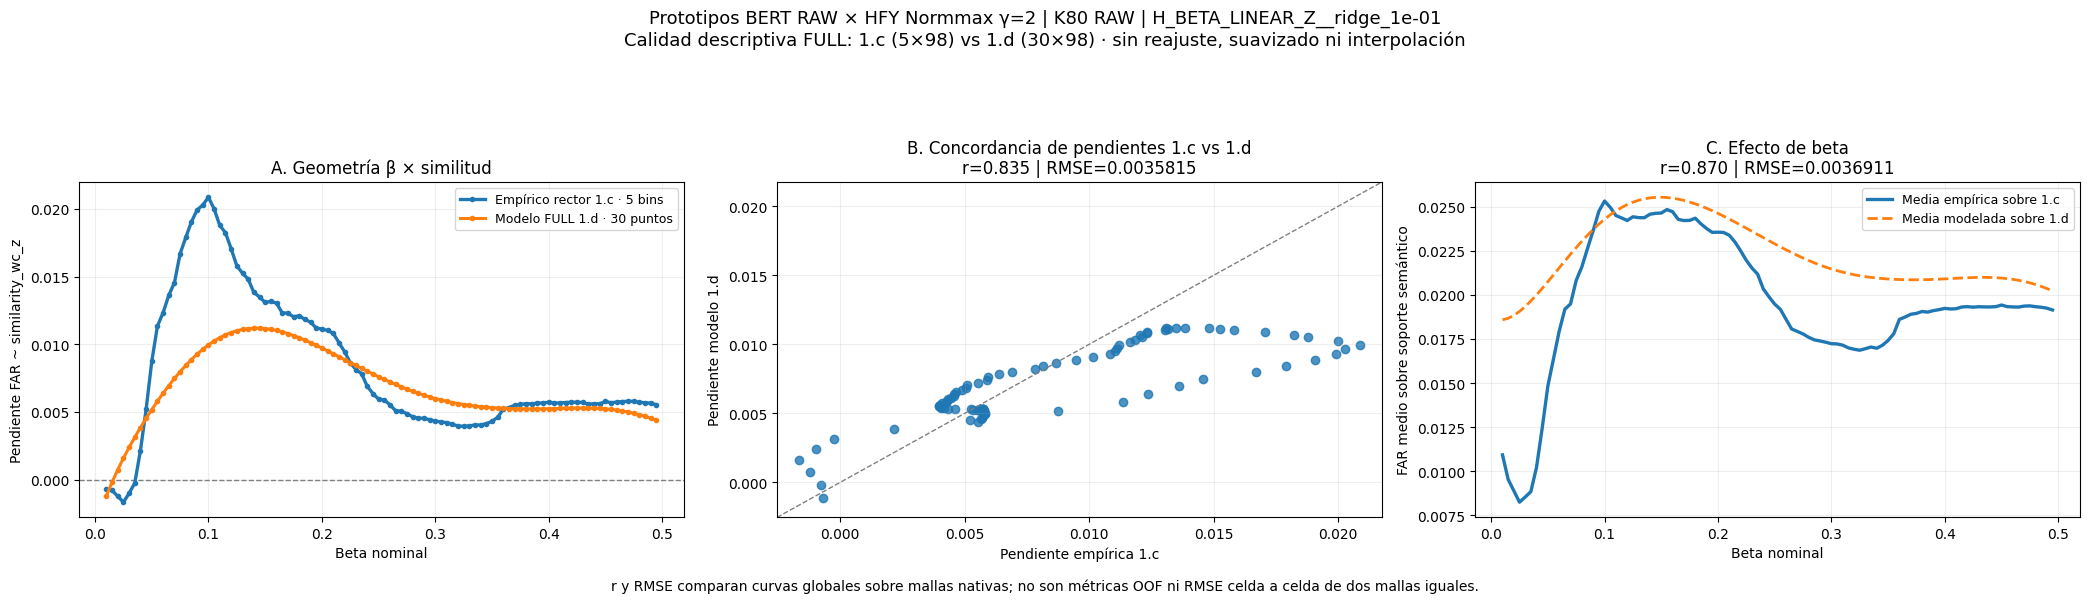


BEGIN_COPY_TABLE::STATIC_RECTOR_FIT_QUALITY_ABC
       network  pearson_1c_vs_1d_slopes  rmse_1c_vs_1d_slopes  mean_slope_bias_model_minus_empirical  pearson_beta_mean_curve  rmse_beta_mean_curve  empirical_beta_far_spearman  model_beta_far_spearman  empirical_attenuation_spearman  model_attenuation_spearman  empirical_T1  empirical_T2  empirical_T3  model_T1  model_T2  model_T3  RMSE_full_predictions_at_words_5bins                                role
 mhncs_softmax                 0.898124              0.003448                              -0.001119                 0.691858              0.005112                    -0.406078                -0.929741                       -0.516847                   -0.726846      0.007230     -0.015833     -0.024124  0.006111 -0.017979 -0.014978                              0.012173 FULL_DESCRIPTIVE_NOT_OOF_NOT_A_GATE
hfy_entmax_a15                 0.779621              0.002761                              -0.000924                 0.904481          

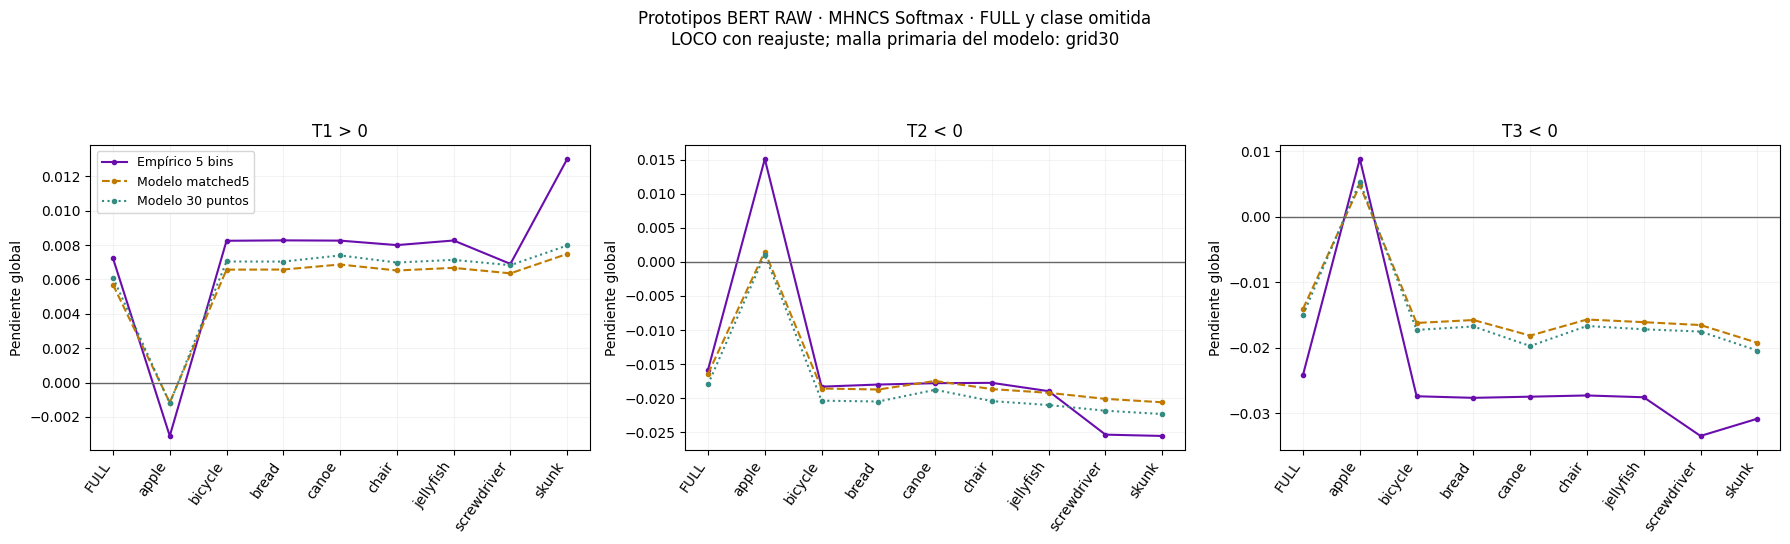

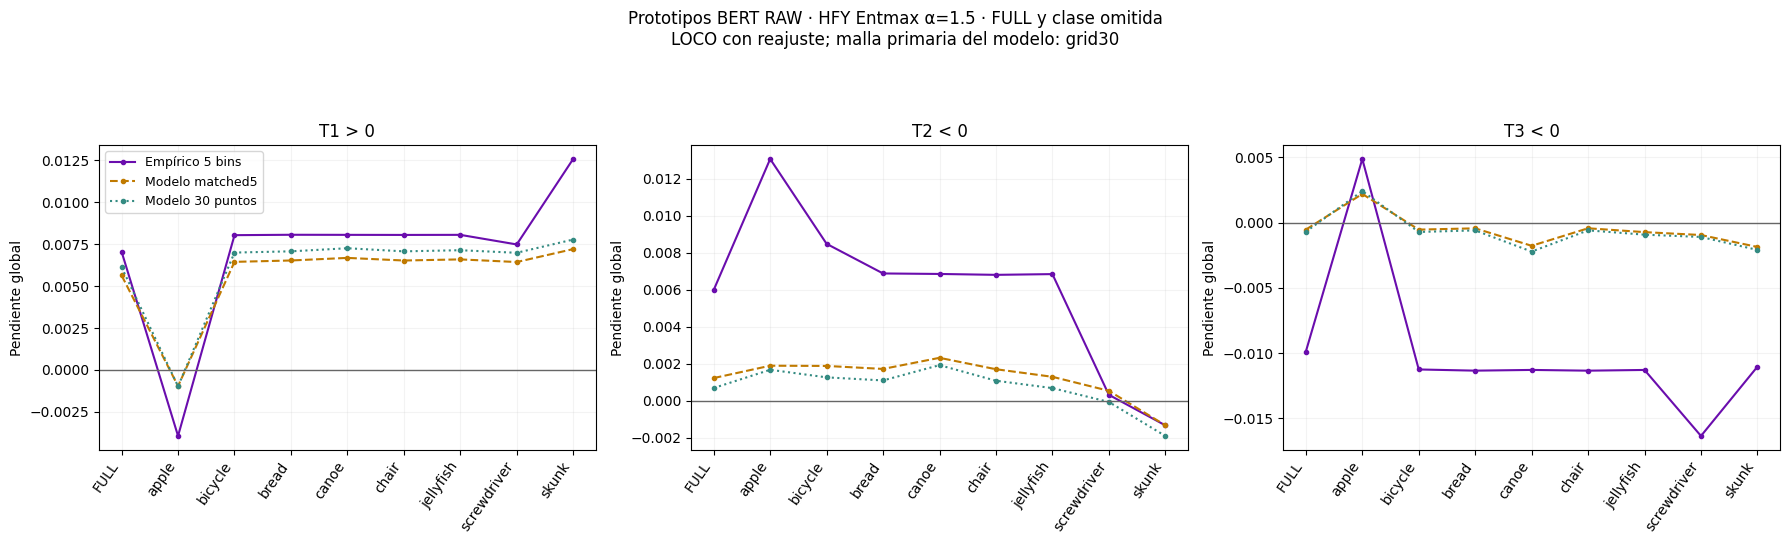

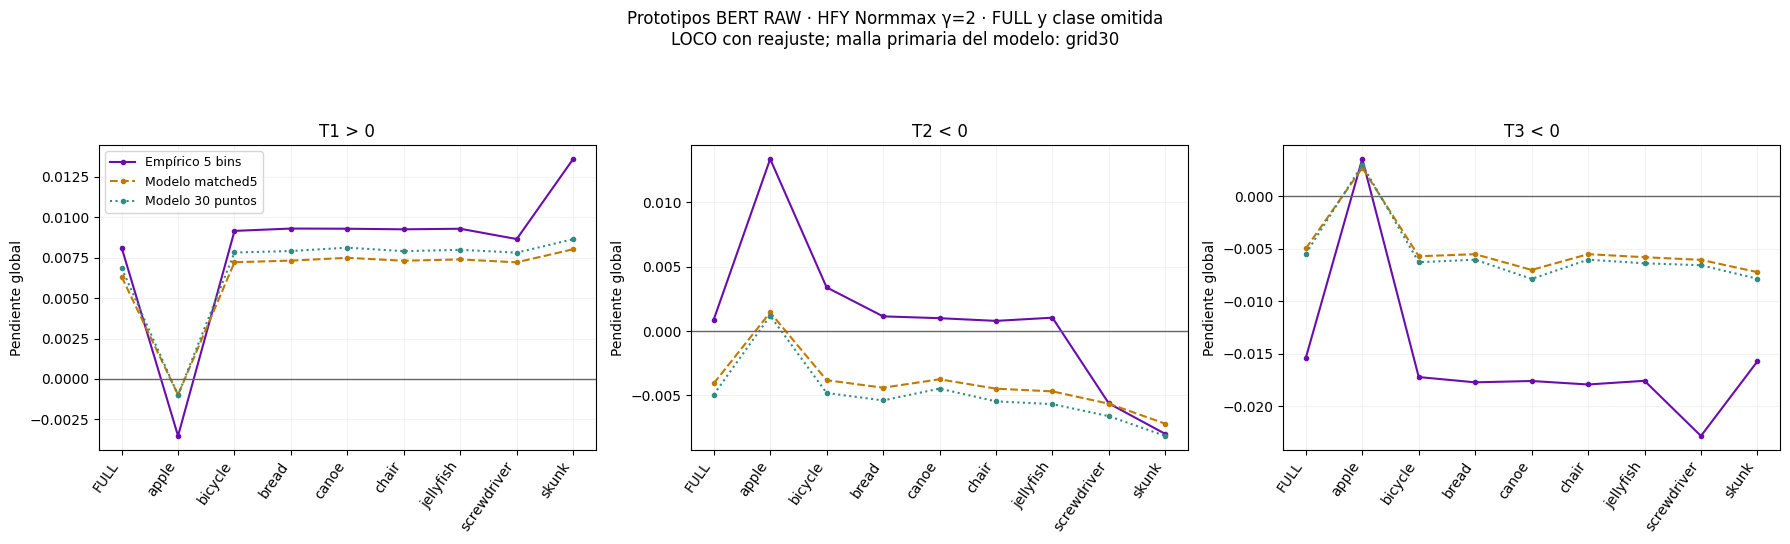

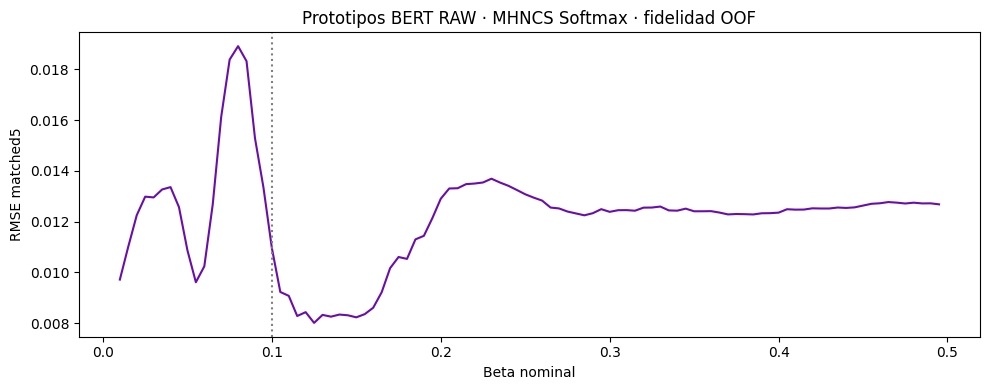

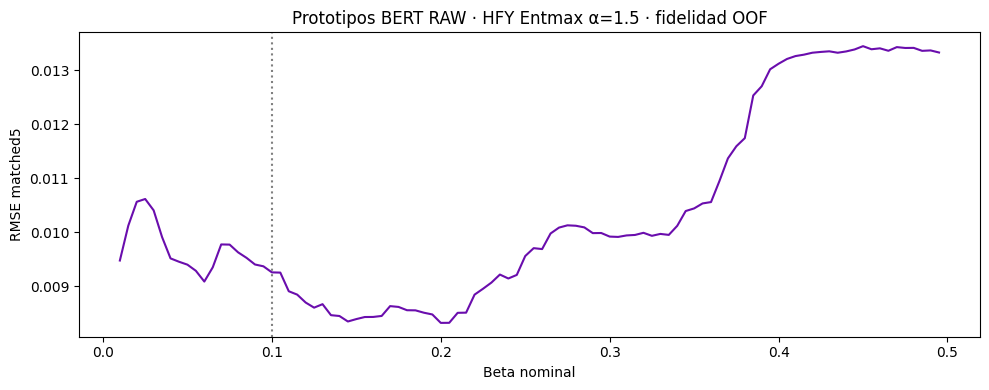

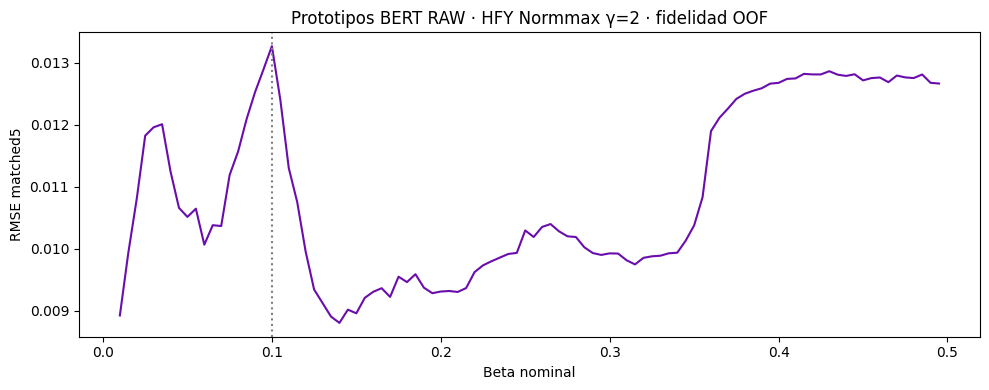


Prototipos BERT RAW · OOF_fidelity


,network,region,RMSE,MAE,bias,max_abs_error,role
0,mhncs_softmax,ALL,0.012299,0.009941,0.002294,0.032197,OOF_REPEAT_AVERAGED_5
1,mhncs_softmax,BETA_LE_0.10,0.013600,0.011403,0.001517,0.032197,OOF_REPEAT_AVERAGED_5
2,mhncs_softmax,BETA_GT_0.10,0.011965,0.009589,0.002481,0.020823,OOF_REPEAT_AVERAGED_5
3,hfy_entmax_a15,ALL,0.010526,0.008580,0.002333,0.022005,OOF_REPEAT_AVERAGED_5
4,hfy_entmax_a15,BETA_LE_0.10,0.009691,0.008256,0.004720,0.016039,OOF_REPEAT_AVERAGED_5
5,hfy_entmax_a15,BETA_GT_0.10,0.010717,0.008657,0.001759,0.022005,OOF_REPEAT_AVERAGED_5
6,hfy_normmax_g2,ALL,0.010987,0.009191,0.002542,0.020868,OOF_REPEAT_AVERAGED_5
7,hfy_normmax_g2,BETA_LE_0.10,0.011254,0.010075,0.004800,0.016937,OOF_REPEAT_AVERAGED_5
8,hfy_normmax_g2,BETA_GT_0.10,0.010922,0.008979,0.001999,0.020868,OOF_REPEAT_AVERAGED_5



Prototipos BERT RAW · sensitivity


,network,fit,omitted_class,omitted_label,empirical_E,M_matched5,M_grid30,stable,RMSE_matched5,MAE_matched5,...,max_abs_error,empirical_T1,empirical_T2,empirical_T3,matched5_T1,matched5_T2,matched5_T3,grid30_T1,grid30_T2,grid30_T3
0,mhncs_softmax,FULL,NaN,NaN,True,True,True,True,0.012173,0.009823,...,0.031914,0.007230,-0.015833,-0.024124,0.005695,-0.016417,-0.014046,0.006111,-0.017979,-0.014978
1,mhncs_softmax,LOCO_0_apple,0.0,apple,False,False,False,True,0.009915,0.009259,...,0.017571,-0.003107,0.015126,0.008848,-0.001162,0.001520,0.004818,-0.001212,0.001048,0.005361
2,mhncs_softmax,LOCO_1_bicycle,1.0,bicycle,True,True,True,True,0.013938,0.011937,...,0.037916,0.008249,-0.018315,-0.027427,0.006569,-0.018590,-0.016222,0.007043,-0.020375,-0.017284
3,mhncs_softmax,LOCO_2_bread,2.0,bread,True,True,True,True,0.013878,0.011215,...,0.036242,0.008272,-0.018006,-0.027670,0.006574,-0.018735,-0.015773,0.007037,-0.020498,-0.016758
4,mhncs_softmax,LOCO_3_canoe,3.0,canoe,True,True,True,True,0.013783,0.011085,...,0.036333,0.008257,-0.017807,-0.027493,0.006868,-0.017478,-0.018155,0.007395,-0.018775,-0.019747
5,mhncs_softmax,LOCO_4_chair,4.0,chair,True,True,True,True,0.013669,0.011086,...,0.032354,0.007997,-0.017758,-0.027306,0.006519,-0.018673,-0.015695,0.006982,-0.020439,-0.016684
6,mhncs_softmax,LOCO_5_jellyfish,5.0,jellyfish,True,True,True,True,0.013976,0.012046,...,0.039421,0.008264,-0.018978,-0.027581,0.006673,-0.019225,-0.016100,0.007137,-0.021017,-0.017189
7,mhncs_softmax,LOCO_6_screwdriver,6.0,screwdriver,True,True,True,True,0.011706,0.009265,...,0.037167,0.006903,-0.025366,-0.033495,0.006352,-0.020107,-0.016540,0.006826,-0.021855,-0.017533
8,mhncs_softmax,LOCO_7_skunk,7.0,skunk,True,True,True,True,0.012209,0.010956,...,0.040454,0.013007,-0.025557,-0.030864,0.007483,-0.020615,-0.019251,0.007974,-0.022337,-0.020437
9,hfy_entmax_a15,FULL,NaN,NaN,False,False,False,True,0.010423,0.008505,...,0.021808,0.007050,0.005983,-0.009885,0.005638,0.001217,-0.000536,0.006126,0.000678,-0.000698



Prototipos BERT RAW · trend_concentration


,trend,unit,total,signed_total,sum_absolute_contributions,max_absolute_contribution_share,effective_absolute_contributors,net_to_absolute_ratio,expected_direction_mass,opposing_direction_mass,top_unit,top_signed_contribution,reconstruction_absolute_error,role,network
0,T1,WORD,0.007230,0.007230,0.019076,0.279553,8.075720,0.379028,0.013153,0.005923,skeet,-0.005333,0.000000e+00,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
1,T1,CLASS,0.007230,0.007230,0.015549,0.639823,2.054592,0.464984,0.011390,0.004160,apple,0.009949,1.734723e-18,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
2,T2,WORD,-0.015833,0.015833,0.053025,0.126422,18.028964,0.298589,0.034429,0.018596,screw,-0.006703,0.000000e+00,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
3,T2,CLASS,-0.015833,0.015833,0.043550,0.667465,2.041859,0.363550,0.029691,0.013859,apple,0.029068,0.000000e+00,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
4,T3,WORD,-0.024124,0.024124,0.051679,0.149228,12.095991,0.466794,0.037901,0.013778,arrow,0.007712,3.469447e-18,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
5,T3,CLASS,-0.024124,0.024124,0.040452,0.787723,1.557483,0.596343,0.032288,0.008164,apple,0.031865,0.000000e+00,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,mhncs_softmax
6,T1,WORD,0.007050,0.007050,0.017723,0.283845,7.272264,0.397771,0.012386,0.005337,skeet,-0.005030,2.602085e-18,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,hfy_entmax_a15
7,T1,CLASS,0.007050,0.007050,0.014972,0.700599,1.779929,0.470845,0.011011,0.003961,apple,0.010489,1.734723e-18,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,hfy_entmax_a15
8,T2,WORD,0.005983,-0.005983,0.035409,0.167150,11.145220,0.168958,0.014713,0.020696,polaroid,0.005919,4.336809e-18,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,hfy_entmax_a15
9,T2,CLASS,0.005983,-0.005983,0.019819,0.361032,3.399685,0.301873,0.006918,0.012901,skunk,-0.007155,3.469447e-18,DESCRIPTIVE_ONLY_NOT_SELECTION_OR_LOCO,hfy_entmax_a15



Prototipos BERT RAW · reuse


,stage,dataset,K,network,path,identity,sha256,action,candidate,fits,fit
0,counts,prototypes,80.0,mhncs_softmax,\\?\C:\Users\jisaa\Workspace\Tesis\Exp2def\Res...,e912cb3f56b89e315a2ce88763a12cb34aaa04c42b7b1b...,4830df56c3b4649b8940acd185de43d2cbae75001d1281...,VERIFIED_REUSE,NaN,NaN,NaN
1,counts,prototypes,80.0,hfy_entmax_a15,\\?\C:\Users\jisaa\Workspace\Tesis\Exp2def\Res...,56347d2e6885bc416b7347c1ececcbf56cbac26ca552a8...,fe2169dca9b9cea49c8a1a2eab04884a6bb051f1c68c39...,VERIFIED_REUSE,NaN,NaN,NaN
2,counts,prototypes,80.0,hfy_normmax_g2,\\?\C:\Users\jisaa\Workspace\Tesis\Exp2def\Res...,39fa1131b3c8fce3dc25623a5e47bf366bc67457acaaea...,6d66a8cd3151954e5e0d296029c264594628650591ad61...,VERIFIED_REUSE,NaN,NaN,NaN
3,model_selection,NaN,NaN,NaN,\\?\C:\Users\jisaa\Workspace\Tesis\Exp2def\Res...,NaN,NaN,VERIFIED_REUSE,H_BETA_LINEAR_Z__ridge_1e-01,3825.0,NaN
4,FULL_LOCO,NaN,NaN,mhncs_softmax,\\?\C:\Users\jisaa\Workspace\Tesis\Exp2def\Res...,NaN,NaN,VERIFIED_REUSE,NaN,NaN,FULL
5,FULL_LOCO,NaN,NaN,mhncs_softmax,\\?\C:\Users\jisaa\Workspace\Tesis\Exp2def\Res...,NaN,NaN,VERIFIED_REUSE,NaN,NaN,LOCO_0_apple
6,FULL_LOCO,NaN,NaN,mhncs_softmax,\\?\C:\Users\jisaa\Workspace\Tesis\Exp2def\Res...,NaN,NaN,VERIFIED_REUSE,NaN,NaN,LOCO_1_bicycle
7,FULL_LOCO,NaN,NaN,mhncs_softmax,\\?\C:\Users\jisaa\Workspace\Tesis\Exp2def\Res...,NaN,NaN,VERIFIED_REUSE,NaN,NaN,LOCO_2_bread
8,FULL_LOCO,NaN,NaN,mhncs_softmax,\\?\C:\Users\jisaa\Workspace\Tesis\Exp2def\Res...,NaN,NaN,VERIFIED_REUSE,NaN,NaN,LOCO_3_canoe
9,FULL_LOCO,NaN,NaN,mhncs_softmax,\\?\C:\Users\jisaa\Workspace\Tesis\Exp2def\Res...,NaN,NaN,VERIFIED_REUSE,NaN,NaN,LOCO_4_chair


In [11]:
if "prototypes" in RESULTS:
    exp.plot_dataset(RESULTS["prototypes"], heatmaps=False, fit_quality=True, oof=True)
    exp.display_tables(RESULTS["prototypes"], names=(
        "OOF_fidelity", "sensitivity", "trend_concentration", "reuse"
    ))

## 4. Cierre de AA

Estas filas corresponden sólo a prototipos K80. No se mezclan con GloVe/W2V ni con condiciones de ocurrencias.
El criterio de lectura conserva los resultados del cierre original.


In [ ]:
if RESULTS:
    final = pd.concat([
        result.tables["final_status"].assign(dataset=key, K=result.context["K"],
            model=result.summary["model"], dataset_CORE3_PASS=result.summary["CORE3_PASS"])
        for key, result in RESULTS.items()
    ], ignore_index=True)
    columns = ["dataset", "K", "network", "model", "E_empirical", "empirical_LOCO_passed",
               "primary_model_grid", "M_primary", "R_MODEL_primary", "B_report",
               "ALL_FITS_STABLE", "dataset_CORE3_PASS"]
    display(final[columns])
    print("Datasets completos:", ", ".join(RESULTS))
    if set(RESULTS) != set(CONFIG.datasets):
        print("Faltan datasets: el resumen conjunto aún es parcial.")

## 5. Informes y reutilización

El modo `reuse_only` reconstruye informes, predicciones y gráficos desde los resultados AA guardados.
No ejecuta clasificadores ni ajusta coeficientes nuevos. El cargador original verifica 3.825 checkpoints
CV y 27 FULL/LOCO cuando están disponibles sus carpetas completas.

Las salidas ya visibles se conservaron del notebook enviado; no se volvieron a verificar integralmente
en esta entrega por falta de sus carpetas externas. Consulta `RESULTADOS_PENDIENTES.md` para conectarlas.
La generación del dataset de prototipos y las otras condiciones del estudio contextual se incorporarán
por separado. Esta organización no convierte el cierre exploratorio original en una certificación CORE3.


In [ ]:
for key, result in RESULTS.items():
    print(f"{key}: {result.output_dir}")
    print("  Informe:", result.output_dir / "report" / "RUN_REPORT.md")
    print("  Resumen:", result.output_dir / "report" / "summary.json")
    print("  Figuras:", result.context["out88"] / "figures")